# Task for session2_cont and session3: 
## Edge-Preserving Denoising Filters & Feature Matching

**Instructions:**  
**please dont use .py to solve this task, just use tasks2.ipynb and edit the cells.**
- After forking the [SkyXperts-Vision-Course repo](https://github.com/ffathy-tdx/SkyXperts-Vision-Course) on GitHub. (you should have already dont this in the last session & uploaded task1)
- Go to your fork of the repo on GitHub.
- At the top, look for a yellow box that says “This branch is X commits behind…”
- Click the Sync fork or Update branch button.
The new task will show up in your tasks/ folder.  
- Upload your task to your forked repo (like you've done with task1 before)
---

## 1. DoG, LoG, and Edge-Preserving Denoising Filters

**Task:**
- Briefly read the descriptions below, then apply each filter to `'sample.jpg'` (or any test image you choose).
- Compare the results visually and write your observations.

**Background:**
- **DoG (Difference of Gaussian):** Used for edge detection by subtracting two blurred versions of the image (with different Gaussian sigmas).
- **LoG (Laplacian of Gaussian):** Uses a single Gaussian blur followed by Laplacian to highlight regions of rapid intensity change (edges).
- **Edge-Preserving Denoising (Bilateral Filter):** Smooths image while preserving edges (unlike simple Gaussian blur). You've already used this at the end of task1.

---

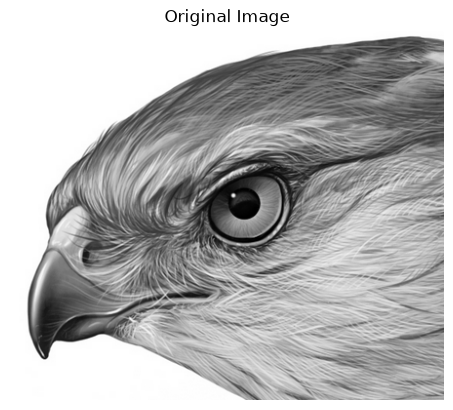

In [2]:
# Import required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
path=r'D:\Documents\term\Skyxpert\cv\SkyXperts-Vision-Course-master\Session2\images\hawk.png'
# Load image
img = cv2.imread(path, 0)  # Use grayscale for filtering
plt.imshow(img, cmap='gray'); plt.axis('off'); plt.title('Original Image'); 
plt.show()

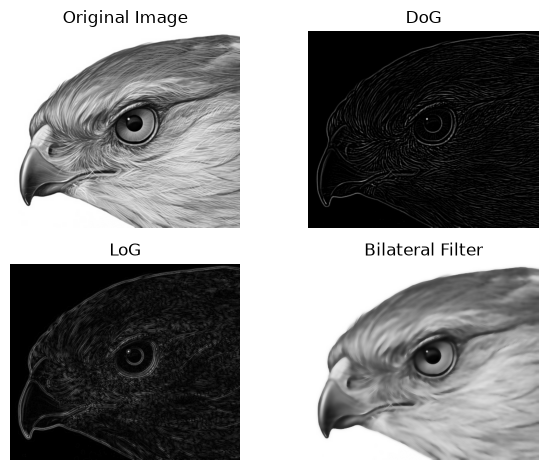

In [3]:
# 1. DoG 
blur1 = cv2.GaussianBlur(img, (5, 5), 1)
blur2 = cv2.GaussianBlur(img, (5, 5), 2)
dog = cv2.subtract(blur1, blur2)

# 2. LoG 
gaussian = cv2.GaussianBlur(img, (5, 5), 1)
log = cv2.Laplacian(gaussian, cv2.CV_64F)
log = np.uint8(np.absolute(log))

# 3. Bilateral Filter
bilateral = cv2.bilateralFilter(img, 9, 75, 75)

# Display all results
images = [img, dog, log, bilateral]

titles = [
    'Original Image',
    'DoG',
    'LoG',
    'Bilateral Filter'
]

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

**Q1: What differences do you observe between DoG, LoG, and the edge-preserving filter?**

_Write your observations here._

## 2. Keypoints & Descriptors: SIFT vs. ORB

**Task:**
- Detect and plot keypoints on `'sample.jpg'` using SIFT and ORB.
- Compare the number and distribution of detected keypoints.

**Background:**
- **Keypoints:** Distinctive image points (corners/blobs) useful for matching.
- **Descriptors:** Vectors that describe local patches around keypoints for comparison/matching.

---

Number of SIFT keypoints: 961
Number of ORB keypoints: 500


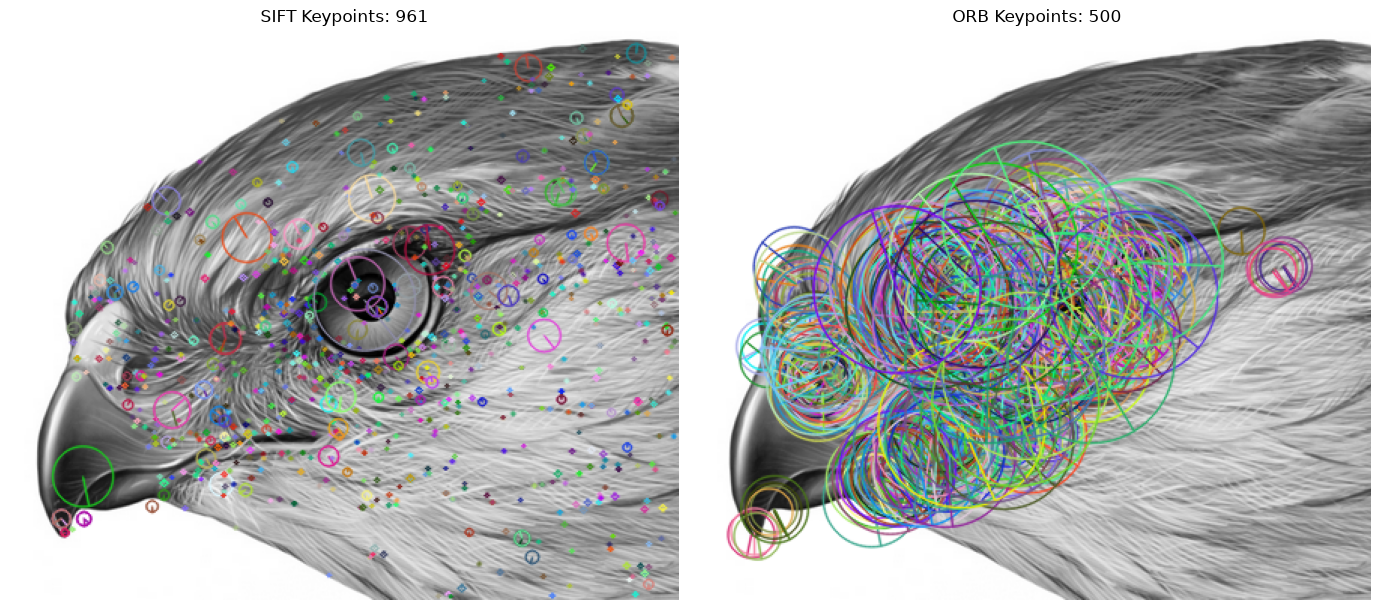

In [4]:
# Detect and plot SIFT keypoints
sift = cv2.SIFT_create()

kp_sift, des_sift = sift.detectAndCompute(img, None)

# Draw SIFT keypoints
img_sift = cv2.drawKeypoints(
    img, kp_sift, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Detect and plot ORB keypoints
orb = cv2.ORB_create()

kp_orb, des_orb = orb.detectAndCompute(img, None)

# Draw ORB keypoints
img_orb = cv2.drawKeypoints(
    img, kp_orb, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Count keypoints
print("Number of SIFT keypoints:", len(kp_sift))
print("Number of ORB keypoints:", len(kp_orb))

# Display results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_sift, cmap='gray')
plt.title(f'SIFT Keypoints: {len(kp_sift)}')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_orb, cmap='gray')
plt.title(f'ORB Keypoints: {len(kp_orb)}')
plt.axis('off')

plt.tight_layout()
plt.show()

**Q2: How do the number and distribution of keypoints differ between SIFT and ORB?**

_Write your answer here._

## 3. Feature Matching with Descriptors

**Task:**
- Load a second image (e.g., `'sample2.jpg'`).
- Detect keypoints/descriptors using SIFT or ORB in both images.
- Match the features between the images using BFMatcher or FLANN.
- Plot the top matches.

**Background:**
- **Feature matching** helps recognize objects/scenes or estimate image transformations.

---

Keypoints in image 1: 961
Keypoints in image 2: 2212
Total matches: 961
Good matches: 4


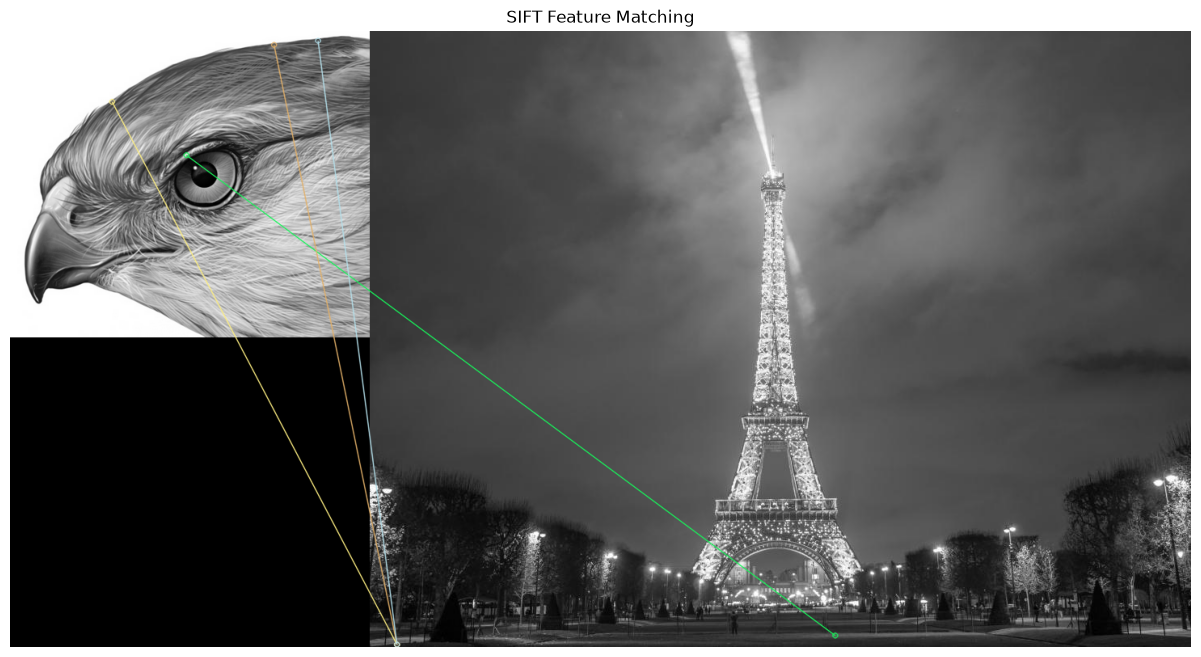

In [5]:
# Load second image
img2 = cv2.imread(r'D:\Documents\term\Skyxpert\cv\SkyXperts-Vision-Course-master\Session3\images\eiffel1.jpg', 0)

if img2 is None:
    print("Error: Could not load sample2.jpg")

else:
    # Detect SIFT keypoints/descriptors in both images
    sift = cv2.SIFT_create()

    kp1, des1 = sift.detectAndCompute(img, None)
    kp2, des2 = sift.detectAndCompute(img2, None)

    # BFMatcher with default params
    bf = cv2.BFMatcher()

    # Match descriptors using KNN
    matches = bf.knnMatch(des1, des2, k=2)

    # Apply Lowe's Ratio Test to remove weak matches
    good_matches = []

    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

    # Sort matches by distance
    good_matches = sorted(good_matches, key=lambda x: x.distance)

    # Draw top matches
    result = cv2.drawMatches(
        img, kp1,
        img2, kp2,
        good_matches[:30],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # Display results
    print("Keypoints in image 1:", len(kp1))
    print("Keypoints in image 2:", len(kp2))
    print("Total matches:", len(matches))
    print("Good matches:", len(good_matches))

    plt.figure(figsize=(16, 8))
    plt.imshow(result, cmap='gray')
    plt.title('SIFT Feature Matching')
    plt.axis('off')
    plt.show()

**Q3: What do you notice about the feature matches? Are there any mismatches or errors? How might you improve the matching process?**

_Write your answer here._

**Bonus Task (Optional, for extra credit):**
- Try using different image preprocessing steps *before* edge detection or feature extraction.
    - For example:
        - Add noise to your image (e.g., Gaussian noise, salt-and-pepper noise).
        - Apply a sharpening filter to your image.
    - Then, run DoG, LoG, or any edge-preserving filter and observe the changes.
- **What to do:**
    - Show the results (images/plots) for at least one type of preprocessing + edge detection.
    - Briefly explain:
        - How does noise affect edge maps or keypoints?
        - Does sharpening make features easier or harder to detect/match?

**You can add your code and observations in the cells below.**


In [6]:
# Write your code here

_What are your observations?_
write them here

## 4. Reflection (Optional)

- What was the most challenging or interesting part of this task for you?
- Any feedback or thoughts?

_Write your reflection here._